# 03 – ICP Registration Check

Compare LAS point clouds before and after ICP registration to visualize deviations.

This notebook compares:
- Original clipped LAS: `tiles_multispectral.109.las`
- ICP registered LAS: `icp/tiles_multispectral.109.las`

In [21]:
from pathlib import Path
import laspy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D

# Configuration
TILE_ID = '109'

# File paths for all four datasets
REFERENCE_LAS = Path('/data/calperumResearch/site1_1_DD0001/imagery/clipped/raster') / f'tiles_multispectral.{TILE_ID}.las'
LIDAR_ORIG_LAS = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/original') / f'tiles_multispectral.{TILE_ID}.las'
LIDAR_COREG_LAS = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg') / f'tiles_multispectral.{TILE_ID}.las'
LIDAR_ICP_LAS = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/icp') / f'tiles_multispectral.{TILE_ID}.las'

print('--- Configuration ---')
print(f'Reference (Imagery): {REFERENCE_LAS}')
print(f'LiDAR Original:     {LIDAR_ORIG_LAS}')
print(f'LiDAR Coreg:        {LIDAR_COREG_LAS}')
print(f'LiDAR ICP:          {LIDAR_ICP_LAS}')
print()
print(f'Reference exists: {REFERENCE_LAS.exists()}')
print(f'Original exists:  {LIDAR_ORIG_LAS.exists()}')
print(f'Coreg exists:     {LIDAR_COREG_LAS.exists()}')
print(f'ICP exists:       {LIDAR_ICP_LAS.exists()}')
print('---------------------')

--- Configuration ---
Reference (Imagery): /data/calperumResearch/site1_1_DD0001/imagery/clipped/raster/tiles_multispectral.109.las
LiDAR Original:     /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/original/tiles_multispectral.109.las
LiDAR Coreg:        /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/tiles_multispectral.109.las
LiDAR ICP:          /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/icp/tiles_multispectral.109.las

Reference exists: True
Original exists:  True
Coreg exists:     True
ICP exists:       True
---------------------


In [26]:
# Load all four point clouds
las_ref = laspy.read(REFERENCE_LAS)
las_orig = laspy.read(LIDAR_ORIG_LAS)
las_coreg = laspy.read(LIDAR_COREG_LAS)
las_icp = laspy.read(LIDAR_ICP_LAS)

print(f'Reference points: {len(las_ref.points):,}')
print(f'Original points:  {len(las_orig.points):,}')
print(f'Coreg points:     {len(las_coreg.points):,}')
print(f'ICP points:       {len(las_icp.points):,}')
print()

# Extract coordinates
x_ref, y_ref, z_ref = las_ref.x, las_ref.y, las_ref.z
x_orig, y_orig, z_orig = las_orig.x, las_orig.y, las_orig.z
x_coreg, y_coreg, z_coreg = las_coreg.x, las_coreg.y, las_coreg.z
x_icp, y_icp, z_icp = las_icp.x, las_icp.y, las_icp.z

# Extract RGB from reference (imagery)
r_ref = las_ref.red
g_ref = las_ref.green
b_ref = las_ref.blue

print('Reference bounds:')
print(f'  X: {las_ref.header.mins[0]:.3f} → {las_ref.header.maxs[0]:.3f}')
print(f'  Y: {las_ref.header.mins[1]:.3f} → {las_ref.header.maxs[1]:.3f}')
print(f'  Z: {las_ref.header.mins[2]:.3f} → {las_ref.header.maxs[2]:.3f}')
print()
print('Original bounds:')
print(f'  X: {las_orig.header.mins[0]:.3f} → {las_orig.header.maxs[0]:.3f}')
print(f'  Y: {las_orig.header.mins[1]:.3f} → {las_orig.header.maxs[1]:.3f}')
print(f'  Z: {las_orig.header.mins[2]:.3f} → {las_orig.header.maxs[2]:.3f}')
print()
print('Coreg bounds:')
print(f'  X: {las_coreg.header.mins[0]:.3f} → {las_coreg.header.maxs[0]:.3f}')
print(f'  Y: {las_coreg.header.mins[1]:.3f} → {las_coreg.header.maxs[1]:.3f}')
print(f'  Z: {las_coreg.header.mins[2]:.3f} → {las_coreg.header.maxs[2]:.3f}')
print()
print('ICP bounds:')
print(f'  X: {las_icp.header.mins[0]:.3f} → {las_icp.header.maxs[0]:.3f}')
print(f'  Y: {las_icp.header.mins[1]:.3f} → {las_icp.header.maxs[1]:.3f}')
print(f'  Z: {las_icp.header.mins[2]:.3f} → {las_icp.header.maxs[2]:.3f}')

Reference points: 722,151
Original points:  1,593,759
Coreg points:     1,593,979
ICP points:       1,593,979

Reference bounds:
  X: 461771.540 → 461802.230
  Y: 6237506.150 → 6237536.850
  Z: 58.420 → 62.830

Original bounds:
  X: 461771.540 → 461802.230
  Y: 6237506.150 → 6237536.840
  Z: 55.400 → 61.220

Coreg bounds:
  X: 461771.540 → 461802.230
  Y: 6237506.150 → 6237536.840
  Z: 55.400 → 61.040

ICP bounds:
  X: 461771.523 → 461802.234
  Y: 6237506.128 → 6237536.839
  Z: 59.408 → 65.073


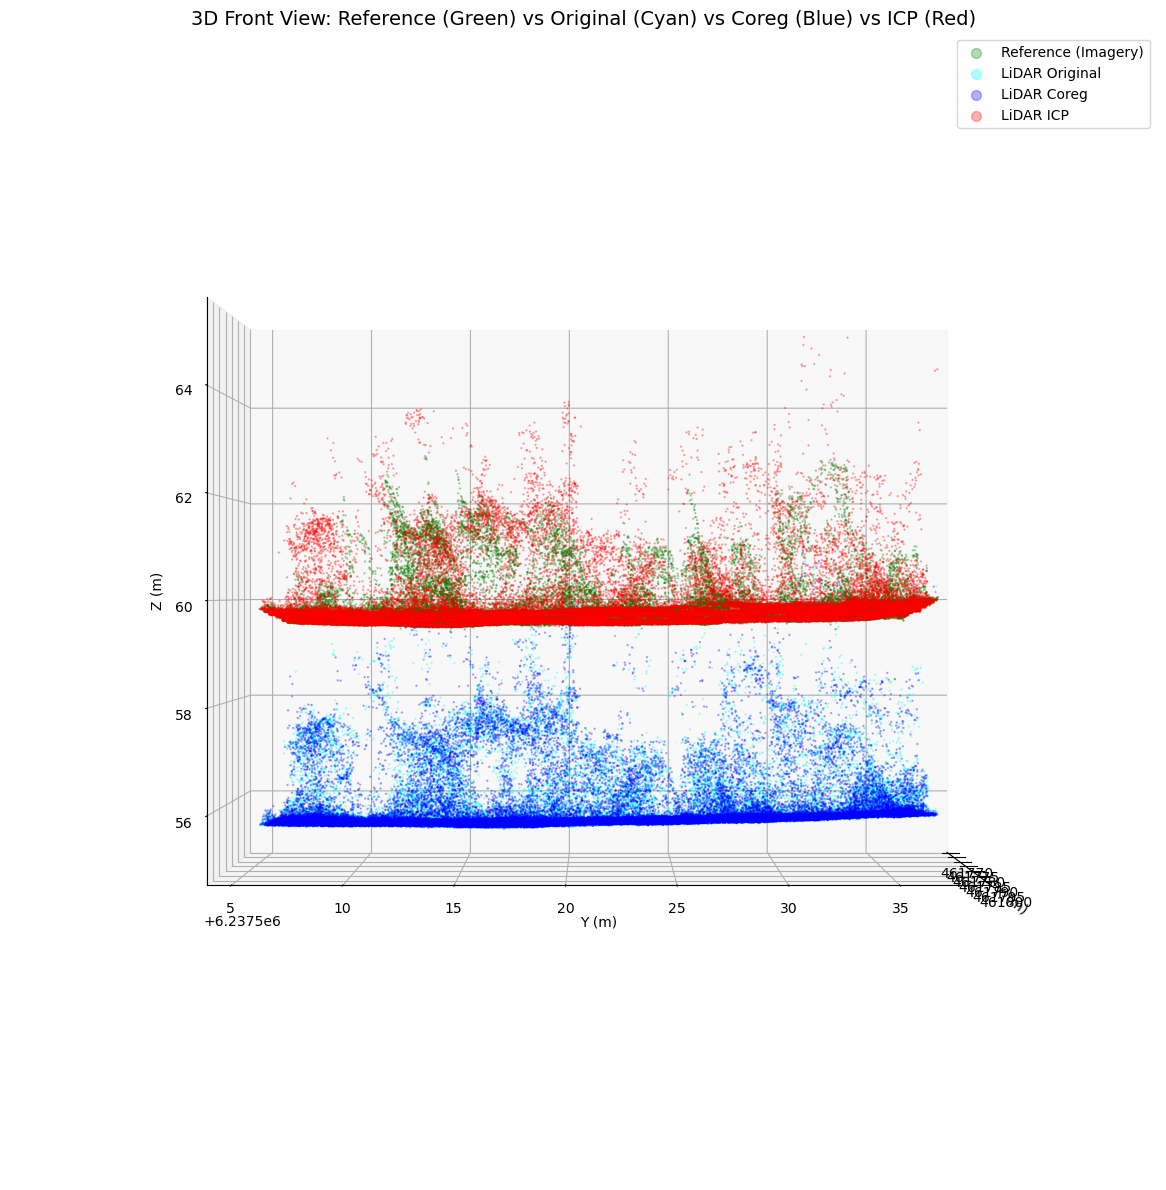

Plotted 50,000 reference points
Plotted 50,000 original points
Plotted 50,000 coreg points
Plotted 50,000 ICP points


In [23]:
# 3D Front View Comparison (all four datasets)
# Downsample for 3D plotting
max_pts_3d = 50000

def downsample_cloud(x, y, z, max_pts):
    n = len(x)
    if n > max_pts:
        idx = np.random.choice(n, size=max_pts, replace=False)
        return x[idx], y[idx], z[idx]
    return x, y, z

x_ref_3d, y_ref_3d, z_ref_3d = downsample_cloud(x_ref, y_ref, z_ref, max_pts_3d)
x_orig_3d, y_orig_3d, z_orig_3d = downsample_cloud(x_orig, y_orig, z_orig, max_pts_3d)
x_coreg_3d, y_coreg_3d, z_coreg_3d = downsample_cloud(x_coreg, y_coreg, z_coreg, max_pts_3d)
x_icp_3d, y_icp_3d, z_icp_3d = downsample_cloud(x_icp, y_icp, z_icp, max_pts_3d)

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot all four point clouds
ax.scatter(x_ref_3d, y_ref_3d, z_ref_3d, c='green', s=0.5, alpha=0.3, label='Reference (Imagery)')
ax.scatter(x_orig_3d, y_orig_3d, z_orig_3d, c='cyan', s=0.5, alpha=0.3, label='LiDAR Original')
ax.scatter(x_coreg_3d, y_coreg_3d, z_coreg_3d, c='blue', s=0.5, alpha=0.3, label='LiDAR Coreg')
ax.scatter(x_icp_3d, y_icp_3d, z_icp_3d, c='red', s=0.5, alpha=0.3, label='LiDAR ICP')

ax.set_xlabel('X (m)', fontsize=10)
ax.set_ylabel('Y (m)', fontsize=10)
ax.set_zlabel('Z (m)', fontsize=10)
ax.set_title('3D Front View: Reference (Green) vs Original (Cyan) vs Coreg (Blue) vs ICP (Red)', fontsize=14)

# Set front view (looking along Y axis)
ax.view_init(elev=0, azim=0)

ax.legend(markerscale=10, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Plotted {len(x_ref_3d):,} reference points')
print(f'Plotted {len(x_orig_3d):,} original points')
print(f'Plotted {len(x_coreg_3d):,} coreg points')
print(f'Plotted {len(x_icp_3d):,} ICP points')

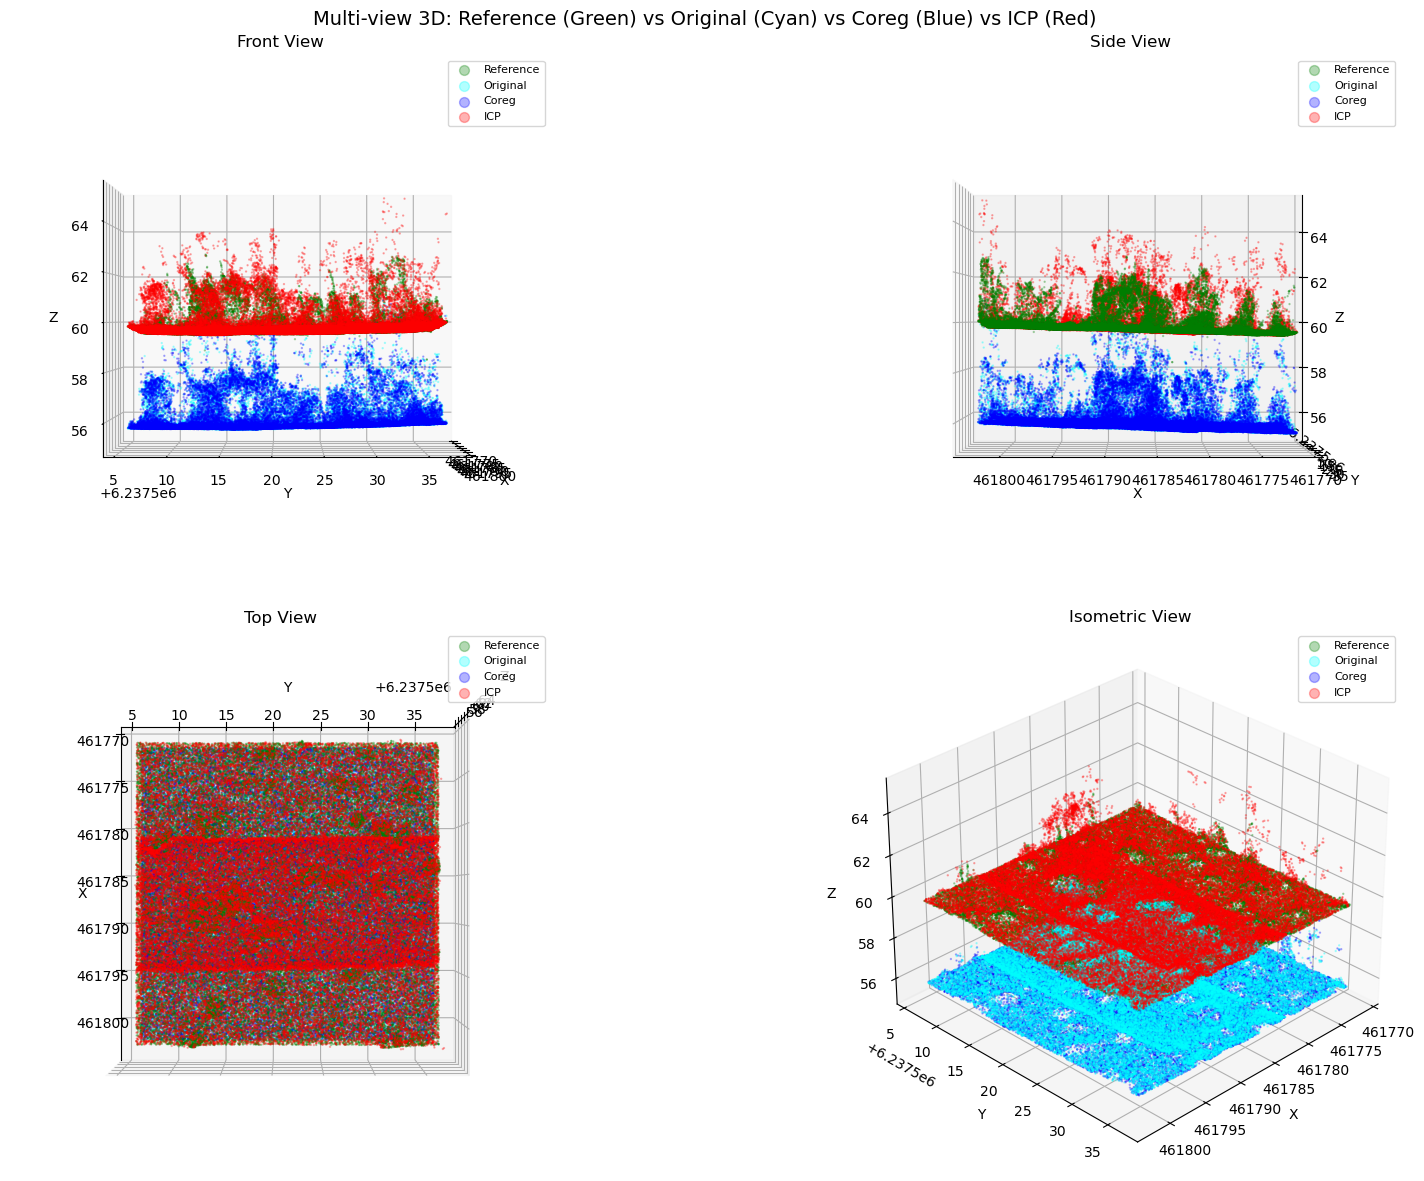

In [24]:
# Multiple 3D views (all four datasets)
fig = plt.figure(figsize=(20, 12))

# Front view (elev=0, azim=0)
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.scatter(x_ref_3d, y_ref_3d, z_ref_3d, c='green', s=0.5, alpha=0.3, label='Reference')
ax1.scatter(x_orig_3d, y_orig_3d, z_orig_3d, c='cyan', s=0.5, alpha=0.3, label='Original')
ax1.scatter(x_coreg_3d, y_coreg_3d, z_coreg_3d, c='blue', s=0.5, alpha=0.3, label='Coreg')
ax1.scatter(x_icp_3d, y_icp_3d, z_icp_3d, c='red', s=0.5, alpha=0.3, label='ICP')
ax1.set_xlabel('X'); ax1.set_ylabel('Y'); ax1.set_zlabel('Z')
ax1.set_title('Front View', fontsize=12)
ax1.view_init(elev=0, azim=0)
ax1.legend(markerscale=10, fontsize=8)

# Side view (elev=0, azim=90)
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.scatter(x_ref_3d, y_ref_3d, z_ref_3d, c='green', s=0.5, alpha=0.3, label='Reference')
ax2.scatter(x_orig_3d, y_orig_3d, z_orig_3d, c='cyan', s=0.5, alpha=0.3, label='Original')
ax2.scatter(x_coreg_3d, y_coreg_3d, z_coreg_3d, c='blue', s=0.5, alpha=0.3, label='Coreg')
ax2.scatter(x_icp_3d, y_icp_3d, z_icp_3d, c='red', s=0.5, alpha=0.3, label='ICP')
ax2.set_xlabel('X'); ax2.set_ylabel('Y'); ax2.set_zlabel('Z')
ax2.set_title('Side View', fontsize=12)
ax2.view_init(elev=0, azim=90)
ax2.legend(markerscale=10, fontsize=8)

# Top view (elev=90, azim=0)
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.scatter(x_ref_3d, y_ref_3d, z_ref_3d, c='green', s=0.5, alpha=0.3, label='Reference')
ax3.scatter(x_orig_3d, y_orig_3d, z_orig_3d, c='cyan', s=0.5, alpha=0.3, label='Original')
ax3.scatter(x_coreg_3d, y_coreg_3d, z_coreg_3d, c='blue', s=0.5, alpha=0.3, label='Coreg')
ax3.scatter(x_icp_3d, y_icp_3d, z_icp_3d, c='red', s=0.5, alpha=0.3, label='ICP')
ax3.set_xlabel('X'); ax3.set_ylabel('Y'); ax3.set_zlabel('Z')
ax3.set_title('Top View', fontsize=12)
ax3.view_init(elev=90, azim=0)
ax3.legend(markerscale=10, fontsize=8)

# Isometric view (elev=30, azim=45)
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.scatter(x_ref_3d, y_ref_3d, z_ref_3d, c='green', s=0.5, alpha=0.3, label='Reference')
ax4.scatter(x_orig_3d, y_orig_3d, z_orig_3d, c='cyan', s=0.5, alpha=0.3, label='Original')
ax4.scatter(x_coreg_3d, y_coreg_3d, z_coreg_3d, c='blue', s=0.5, alpha=0.3, label='Coreg')
ax4.scatter(x_icp_3d, y_icp_3d, z_icp_3d, c='red', s=0.5, alpha=0.3, label='ICP')
ax4.set_xlabel('X'); ax4.set_ylabel('Y'); ax4.set_zlabel('Z')
ax4.set_title('Isometric View', fontsize=12)
ax4.view_init(elev=30, azim=45)
ax4.legend(markerscale=10, fontsize=8)

plt.suptitle('Multi-view 3D: Reference (Green) vs Original (Cyan) vs Coreg (Blue) vs ICP (Red)', fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

In [27]:
# Compute point-wise deviations (Coreg vs ICP)
# Assuming points are in same order (which should be true for ICP registration)
if len(las_coreg.points) == len(las_icp.points):
    dx = x_icp - x_coreg
    dy = y_icp - y_coreg
    dz = z_icp - z_coreg
    
    # 3D Euclidean distance
    dist_3d = np.sqrt(dx**2 + dy**2 + dz**2)
    
    # Horizontal distance (XY plane)
    dist_xy = np.sqrt(dx**2 + dy**2)
    
    print('Deviation Statistics (Coreg → ICP):')
    print(f'  3D distance:')
    print(f'    Mean:   {dist_3d.mean():.6f} m')
    print(f'    Median: {np.median(dist_3d):.6f} m')
    print(f'    Std:    {dist_3d.std():.6f} m')
    print(f'    Max:    {dist_3d.max():.6f} m')
    print(f'    Min:    {dist_3d.min():.6f} m')
    print()
    print(f'  Horizontal distance (XY):')
    print(f'    Mean:   {dist_xy.mean():.6f} m')
    print(f'    Median: {np.median(dist_xy):.6f} m')
    print(f'    Std:    {dist_xy.std():.6f} m')
    print(f'    Max:    {dist_xy.max():.6f} m')
    print()
    print(f'  Vertical deviation (Z):')
    print(f'    Mean:   {dz.mean():.6f} m')
    print(f'    Median: {np.median(dz):.6f} m')
    print(f'    Std:    {dz.std():.6f} m')
    print(f'    Max:    {dz.max():.6f} m')
    print(f'    Min:    {dz.min():.6f} m')
else:
    print('⚠️ Warning: Point counts differ. Cannot compute point-wise deviations.')
    print('Will visualize point clouds separately instead.')

Deviation Statistics (Coreg → ICP):
  3D distance:
    Mean:   4.021107 m
    Median: 4.020025 m
    Std:    0.007517 m
    Max:    4.040099 m
    Min:    4.000000 m

  Horizontal distance (XY):
    Mean:   0.014653 m
    Median: 0.014142 m
    Std:    0.006363 m
    Max:    0.028284 m

  Vertical deviation (Z):
    Mean:   4.021075 m
    Median: 4.020000 m
    Std:    0.007500 m
    Max:    4.040000 m
    Min:    4.000000 m


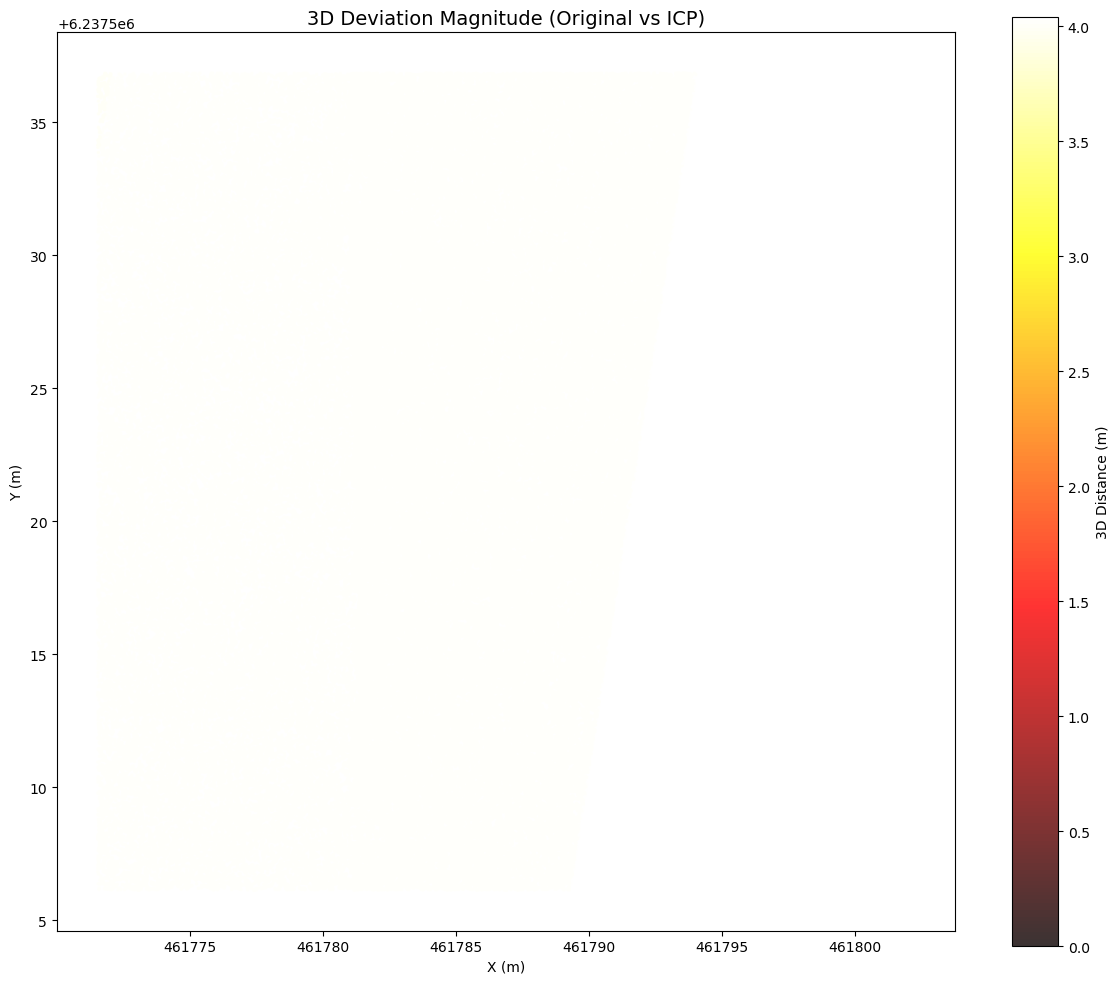

Plotted 200,000 points (downsampled)


In [ ]:
# Visualize deviation magnitude (3D distance: Coreg → ICP)
if len(las_coreg.points) == len(las_icp.points):
    # Downsample for plotting
    n = len(x_coreg)
    max_pts = 200000
    if n > max_pts:
        idx = np.random.choice(n, size=max_pts, replace=False)
        x_plot = x_coreg[idx]
        y_plot = y_coreg[idx]
        dist_plot = dist_3d[idx]
    else:
        x_plot = x_coreg
        y_plot = y_coreg
        dist_plot = dist_3d
    
    # Plot deviation as color-coded scatter
    fig, ax = plt.subplots(figsize=(12, 10))
    sc = ax.scatter(x_plot, y_plot, s=2, c=dist_plot, cmap='hot', alpha=0.8, vmin=0)
    ax.set_title('3D Deviation Magnitude (Coreg vs ICP)', fontsize=14)
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_aspect('equal')
    
    cbar = plt.colorbar(sc, ax=ax, label='3D Distance (m)')
    plt.tight_layout()
    plt.show()
    
    print(f'Plotted {len(x_plot):,} points ({"downsampled" if n > max_pts else "all"})')

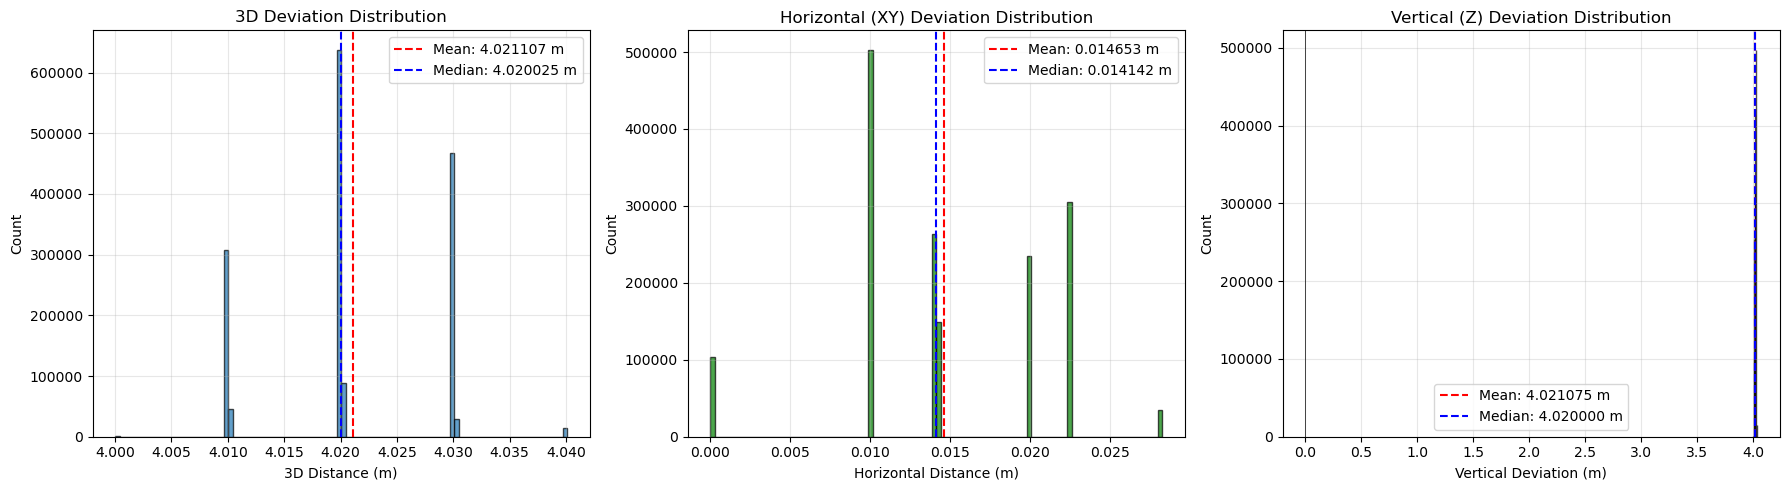

In [28]:
# Deviation histogram (Coreg → ICP)
if len(las_coreg.points) == len(las_icp.points):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 3D distance histogram
    ax = axes[0]
    ax.hist(dist_3d, bins=100, edgecolor='black', alpha=0.7)
    ax.axvline(dist_3d.mean(), color='red', linestyle='--', label=f'Mean: {dist_3d.mean():.6f} m')
    ax.axvline(np.median(dist_3d), color='blue', linestyle='--', label=f'Median: {np.median(dist_3d):.6f} m')
    ax.set_xlabel('3D Distance (m)')
    ax.set_ylabel('Count')
    ax.set_title('3D Deviation Distribution')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Horizontal distance histogram
    ax = axes[1]
    ax.hist(dist_xy, bins=100, edgecolor='black', alpha=0.7, color='green')
    ax.axvline(dist_xy.mean(), color='red', linestyle='--', label=f'Mean: {dist_xy.mean():.6f} m')
    ax.axvline(np.median(dist_xy), color='blue', linestyle='--', label=f'Median: {np.median(dist_xy):.6f} m')
    ax.set_xlabel('Horizontal Distance (m)')
    ax.set_ylabel('Count')
    ax.set_title('Horizontal (XY) Deviation Distribution')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Vertical deviation histogram
    ax = axes[2]
    ax.hist(dz, bins=100, edgecolor='black', alpha=0.7, color='orange')
    ax.axvline(dz.mean(), color='red', linestyle='--', label=f'Mean: {dz.mean():.6f} m')
    ax.axvline(np.median(dz), color='blue', linestyle='--', label=f'Median: {np.median(dz):.6f} m')
    ax.axvline(0, color='black', linestyle='-', linewidth=0.5)
    ax.set_xlabel('Vertical Deviation (m)')
    ax.set_ylabel('Count')
    ax.set_title('Vertical (Z) Deviation Distribution')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_2346955/1596260011.py:42: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


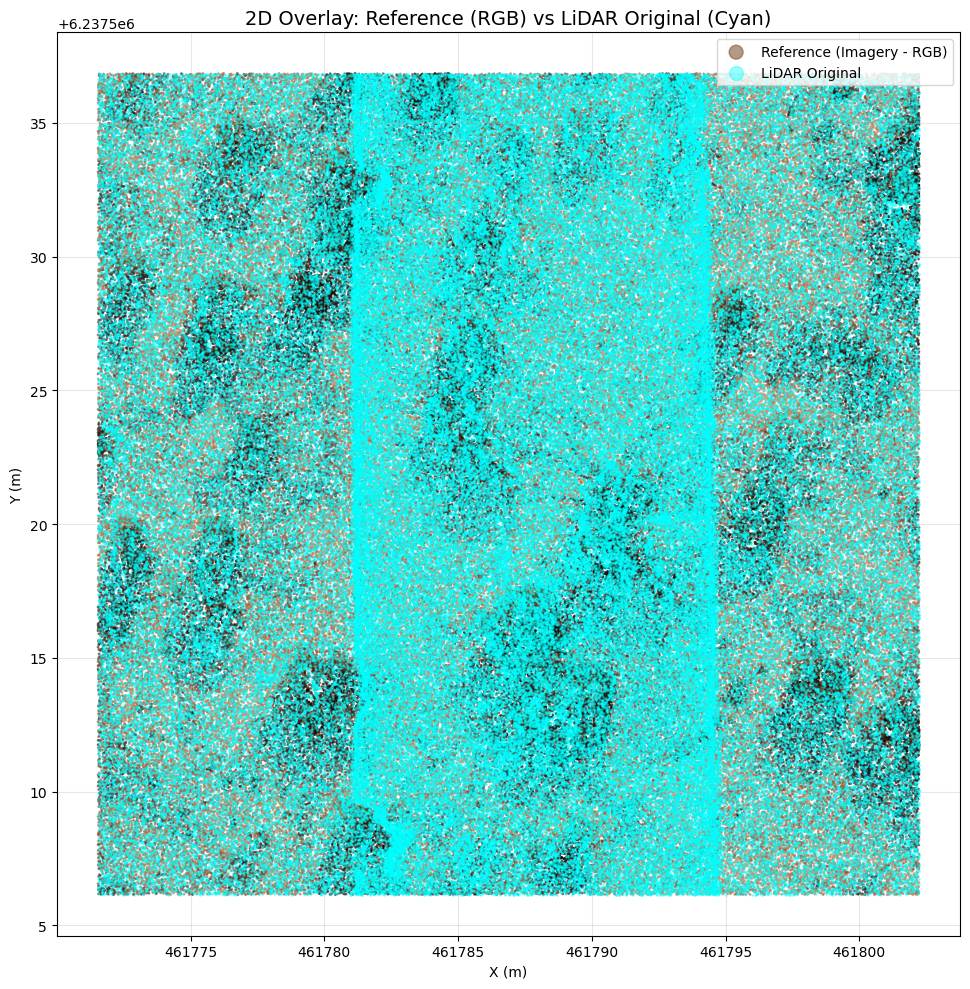

In [29]:
# 2D Overlay: Reference (RGB) vs LiDAR Original
max_pts = 200000

def downsample_2d_rgb(x, y, r, g, b, max_pts):
    n = len(x)
    if n > max_pts:
        idx = np.random.choice(n, size=max_pts, replace=False)
        return x[idx], y[idx], r[idx], g[idx], b[idx], idx
    return x, y, r, g, b, None

def downsample_2d(x, y, max_pts):
    n = len(x)
    if n > max_pts:
        idx = np.random.choice(n, size=max_pts, replace=False)
        return x[idx], y[idx], idx
    return x, y, None

# Downsample reference with RGB
x_ref_plot, y_ref_plot, r_plot, g_plot, b_plot, _ = downsample_2d_rgb(x_ref, y_ref, r_ref, g_ref, b_ref, max_pts)

# Normalize RGB to [0, 1]
rgb_colors = np.stack([r_plot, g_plot, b_plot], axis=-1) / 65535.0

# Downsample original LiDAR
x_orig_plot, y_orig_plot, _ = downsample_2d(x_orig, y_orig, max_pts)

fig, ax = plt.subplots(figsize=(12, 10))

# Plot reference with RGB colors
ax.scatter(x_ref_plot, y_ref_plot, s=1, c=rgb_colors, alpha=0.6, label='Reference (Imagery - RGB)')

# Plot original LiDAR in cyan
ax.scatter(x_orig_plot, y_orig_plot, s=1, c='cyan', alpha=0.4, label='LiDAR Original')

ax.set_title('2D Overlay: Reference (RGB) vs LiDAR Original (Cyan)', fontsize=14)
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_aspect('equal')
ax.legend(markerscale=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

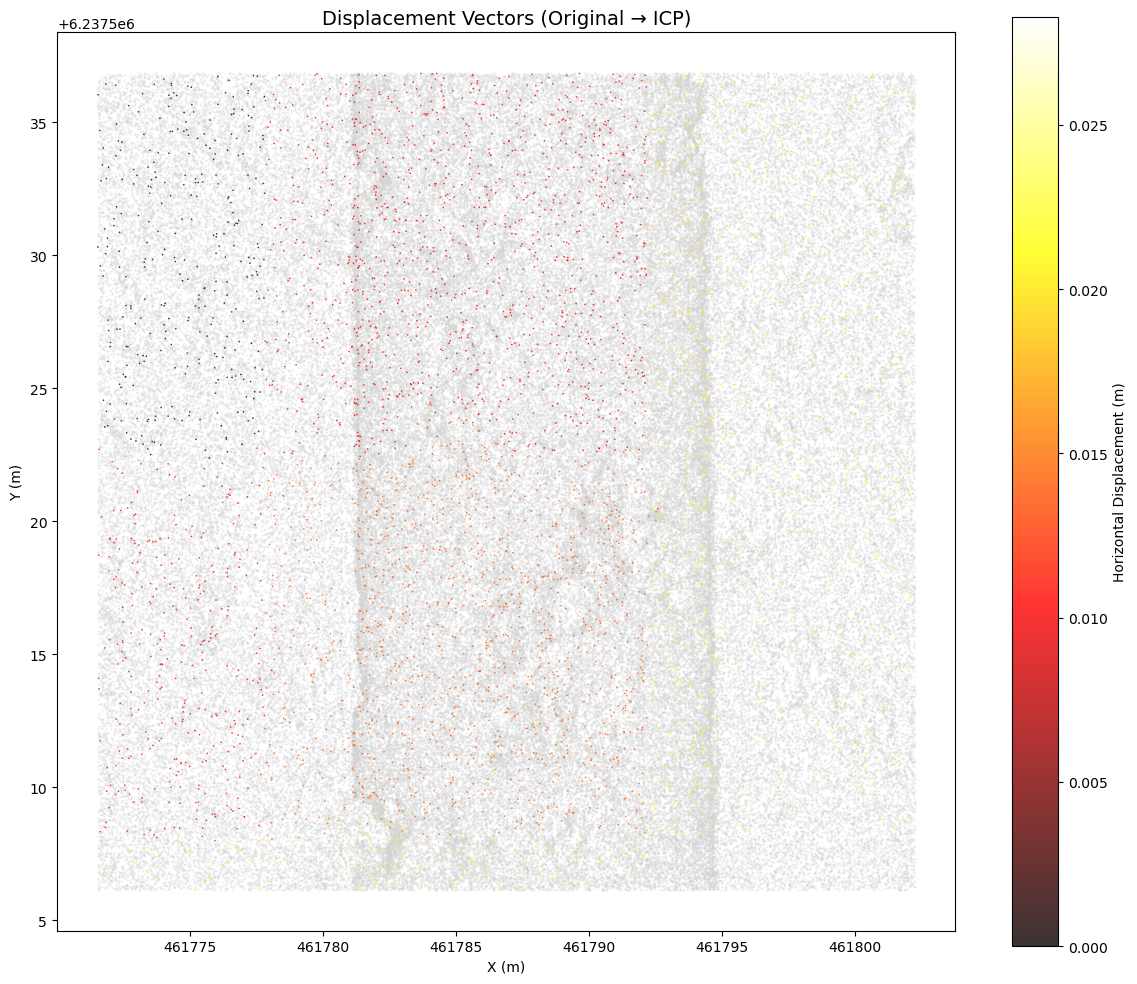

Showing 5,000 displacement vectors


In [ ]:
# Deviation vector field (quiver plot showing displacement: Coreg → ICP)
if len(las_coreg.points) == len(las_icp.points):
    # Heavily downsample for vector visualization
    n_vectors = 5000
    n = len(x_coreg)
    if n > n_vectors:
        idx_vec = np.random.choice(n, size=n_vectors, replace=False)
    else:
        idx_vec = np.arange(n)
    
    x_vec = x_coreg[idx_vec]
    y_vec = y_coreg[idx_vec]
    dx_vec = dx[idx_vec]
    dy_vec = dy[idx_vec]
    dist_vec = dist_xy[idx_vec]
    
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot coreg points as background
    ax.scatter(x_coreg_plot, y_coreg_plot, s=0.5, c='lightgray', alpha=0.3, label='Coreg points')
    
    # Plot displacement vectors colored by magnitude
    quiv = ax.quiver(x_vec, y_vec, dx_vec, dy_vec, dist_vec, 
                     cmap='hot', alpha=0.8, scale=1, scale_units='xy', 
                     angles='xy', width=0.002)
    
    ax.set_title('Displacement Vectors (Coreg → ICP)', fontsize=14)
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_aspect('equal')
    
    cbar = plt.colorbar(quiv, ax=ax, label='Horizontal Displacement (m)')
    plt.tight_layout()
    plt.show()
    
    print(f'Showing {len(idx_vec):,} displacement vectors')

In [ ]:
# Deviation percentiles and summary table (Coreg → ICP)
if len(las_coreg.points) == len(las_icp.points):
    percentiles = [50, 68, 95, 99, 99.9]
    
    print('Deviation Percentiles (Coreg → ICP):')
    print('-' * 60)
    print(f'{"Percentile":<12} {"3D (m)":<15} {"XY (m)":<15} {"Z (m)"}')
    print('-' * 60)
    
    for p in percentiles:
        p_3d = np.percentile(dist_3d, p)
        p_xy = np.percentile(dist_xy, p)
        p_z = np.percentile(np.abs(dz), p)
        print(f'{p:<12.1f} {p_3d:<15.6f} {p_xy:<15.6f} {p_z:.6f}')
    
    print('-' * 60)
    print()
    print('Registration Quality Assessment:')
    print(f'  • {(dist_3d < 0.01).sum() / len(dist_3d) * 100:.2f}% of points within 1 cm')
    print(f'  • {(dist_3d < 0.05).sum() / len(dist_3d) * 100:.2f}% of points within 5 cm')
    print(f'  • {(dist_3d < 0.10).sum() / len(dist_3d) * 100:.2f}% of points within 10 cm')
    print(f'  • {(dist_3d > 0.50).sum() / len(dist_3d) * 100:.2f}% of points with >50 cm deviation')

Deviation Percentiles:
------------------------------------------------------------
Percentile   3D (m)          XY (m)          Z (m)
------------------------------------------------------------
50.0         4.020025        0.014142        4.020000
68.0         4.030025        0.020000        4.030000
95.0         4.030062        0.022361        4.030000
99.0         4.030099        0.028284        4.030000
99.9         4.040099        0.028284        4.040000
------------------------------------------------------------

Registration Quality Assessment:
  • 0.00% of points within 1 cm
  • 0.00% of points within 5 cm
  • 0.00% of points within 10 cm
  • 100.00% of points with >50 cm deviation
99.9         4.040099        0.028284        4.040000
------------------------------------------------------------

Registration Quality Assessment:
  • 0.00% of points within 1 cm
  • 0.00% of points within 5 cm
  • 0.00% of points within 10 cm
  • 100.00% of points with >50 cm deviation
